# Model & Backtester Results

This notebook is the results view for the two *separate* historical-testing tracks in
this repo -- they answer different questions, use different data, and must not be
conflated. Full written framing: README's "Data chronology" section and
`paper/nfl_clv_case_study.md` §3.1/§4.5.

## Track A -- calibration backtest (what's actually running today)
`src/model/train.py` + `src/model/calibration.py`, evaluated in this notebook below.
Trains an EPA-based logistic win-probability model on 2015-2024, tests whether its
probabilities are *calibrated* (Brier score, log loss, reliability) against nflverse's
free historical closing lines as the market baseline.

**This is not a CLV backtest.** nflverse only has one closing number per game -- no
intraday snapshots -- so there's no entry-vs-close pair to compute CLV from. It can only
ever tell you "is this model's probability estimate honest," not "would this model have
beaten the sharp close."

## Track B -- the real CLV backtester (not runnable yet)
`src/backtest/engine.py` replays point-in-time Pinnacle snapshots (entry price at a
decision point vs. Pinnacle's close) and settles P&L + CLV for a strategy. It's fully
built and unit-tested against synthetic fixtures (`tests/test_backtest_engine.py`), but
has **never run against real data**, because there isn't any yet: live collection only
started 2026-08-14, and the regular season (the only source of Pinnacle intraday
history this project has or will backfill) doesn't kick off until 2026-09-10. This
notebook doesn't run Track B for that reason -- there's nothing to run it on. It'll get
its own section here once games start settling.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd

ROOT = Path("..").resolve()
assert (ROOT / "pyproject.toml").exists(), f"unexpected repo root: {ROOT}"

from src.model.baseline import market_baseline
from src.model.calibration import compare_to_baseline, fit_calibrated_model, predict_calibrated_proba
from src.model.evaluate import reliability_curve
from src.model.train import FEATURE_COLUMNS, build_training_frame, fit_win_probability_model, predict_home_win_proba, time_based_split

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)

## Loading the historical data + building the training frame

`schedules_2015_2024.parquet` and `pbp_2015_2024.parquet` are nflverse's free static
pulls (`src/features/load_static.py`) -- schedules carry the closing moneyline used as
the market baseline; play-by-play feeds `src/model/features.py`'s leakage-guarded
pre-game EPA features (see `notebooks/`-adjacent `tests/test_features.py` for the
leakage regression test).

In [2]:
schedule = pd.read_parquet(ROOT / "data" / "static" / "schedules_2015_2024.parquet")
pbp = pd.read_parquet(ROOT / "data" / "static" / "pbp_2015_2024.parquet")

training_df = build_training_frame(pbp, schedule)
print(f"{len(training_df)} games with a usable label + full feature set "
      f"(out of {len(schedule)} total games 2015-2024 -- drops ties and week-1-of-season openers)")
training_df[["game_id", "season", "week", "home_team", "away_team", "home_win", "market_prob_home", *FEATURE_COLUMNS]].head()

2595 games with a usable label + full feature set (out of 2743 total games 2015-2024 -- drops ties and week-1-of-season openers)


,game_id,season,week,home_team,away_team,home_win,market_prob_home,home_pre_off_epa,home_pre_off_success,home_pre_def_epa_allowed,home_pre_def_success_allowed,away_pre_off_epa,away_pre_off_success,away_pre_def_epa_allowed,away_pre_def_success_allowed,home_rest,away_rest,div_game
16,2015_02_DEN_KC,2015,2,KC,DEN,0,0.603343,0.002278,0.432836,-0.130424,0.453333,-0.227019,0.333333,-0.362337,0.293103,4,4,1
17,2015_02_NE_BUF,2015,2,BUF,NE,0,0.539928,0.080444,0.357143,0.009576,0.405405,0.290281,0.533333,0.249406,0.513889,7,10,1
18,2015_02_HOU_CAR,2015,2,CAR,HOU,1,0.574035,-0.088671,0.362319,-0.318733,0.378788,-0.130424,0.453333,0.002278,0.432836,7,7,0
19,2015_02_ARI_CHI,2015,2,CHI,ARI,0,0.469433,0.093701,0.458333,0.391846,0.561404,0.210083,0.459016,-0.020548,0.369863,7,7,0
21,2015_02_TEN_CLE,2015,2,CLE,TEN,1,0.517291,-0.237009,0.388060,0.148887,0.457627,0.301102,0.538462,-0.285730,0.328571,7,7,0


## Train / calibrate / test split

Out-of-time by season -- train (2015-2021), calibrate (2022), test (2023-2024) -- so no
season is used for more than one of {fit model, fit calibration, report results}
(`src/model/train.py::time_based_split`).

In [3]:
train_df, calib_df, test_df = time_based_split(
    training_df, train_seasons=range(2015, 2022), calib_seasons=[2022], test_seasons=[2023, 2024]
)
print(f"train={len(train_df)}  calib={len(calib_df)}  test={len(test_df)} games")

raw_model = fit_win_probability_model(train_df)
calibrated_model = fit_calibrated_model(raw_model, calib_df, method="isotonic")

predictions = {
    "market_baseline": test_df["market_prob_home"],
    "raw_logistic": predict_home_win_proba(raw_model, test_df),
    "calibrated_logistic": predict_calibrated_proba(calibrated_model, test_df),
}

train=1743  calib=282  test=570 games


## Results: Brier score & log loss (test seasons, 2023-2024)

Lower is better on both. The market baseline is the floor every model has to beat
(blueprint Part E) -- most models don't, and that's the expected, honest outcome, not a
bug to chase away.

In [4]:
report = compare_to_baseline(predictions, test_df["home_win"])
report

,model,brier,log_loss
0,market_baseline,0.209862,0.608192
1,calibrated_logistic,0.229434,0.651399
2,raw_logistic,0.231590,0.658831


## Reliability curves

Binned predicted probability vs. observed win frequency (`src/model/evaluate.py::reliability_curve`,
10 bins). A perfectly calibrated model sits on the diagonal. Marker size encodes bin
count (`n`) -- a bin near the diagonal built on 3 games means much less than one built
on 150.

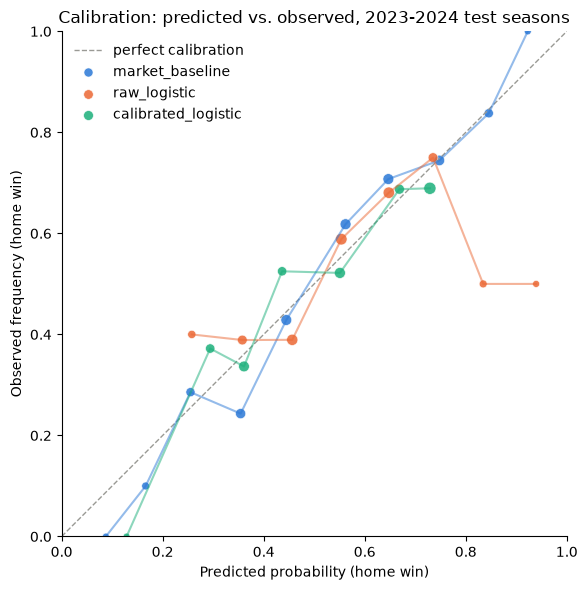

In [5]:
import matplotlib.pyplot as plt

# dataviz skill's categorical slots 1-3 (blue/orange/aqua) -- validated all-pairs CVD-safe
# for exactly 3 series, fixed role assignment (never reassigned if a series is dropped).
COLORS = {
    "market_baseline": "#2a78d6",
    "raw_logistic": "#eb6834",
    "calibrated_logistic": "#1baf7a",
}

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot([0, 1], [0, 1], linestyle="--", linewidth=1, color="#9a9a95", label="perfect calibration")

for name, p in predictions.items():
    curve = reliability_curve(np.asarray(p), test_df["home_win"].to_numpy(), n_bins=10).dropna(subset=["predicted", "observed"])
    sizes = 20 + 4 * np.sqrt(curve["count"])
    ax.scatter(curve["predicted"], curve["observed"], s=sizes, color=COLORS[name], label=name, alpha=0.85, edgecolors="white", linewidths=0.5)
    ax.plot(curve["predicted"], curve["observed"], color=COLORS[name], linewidth=1.5, alpha=0.5)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_xlabel("Predicted probability (home win)")
ax.set_ylabel("Observed frequency (home win)")
ax.set_title("Calibration: predicted vs. observed, 2023-2024 test seasons")
ax.set_aspect("equal")
ax.legend(loc="upper left", frameon=False)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

## What's driving the model

Standardized logistic regression coefficients (the pipeline scales features before
fitting -- `src/model/train.py::fit_win_probability_model` -- so coefficients are
directly comparable in magnitude). Positive = pushes toward a home win.

In [6]:
coefs = pd.Series(raw_model.named_steps["logit"].coef_[0], index=FEATURE_COLUMNS).sort_values(key=abs, ascending=False)
coefs.to_frame("standardized_coefficient")

,standardized_coefficient
away_pre_off_success,-0.212711
away_pre_off_epa,-0.195362
home_pre_off_success,0.190492
home_pre_def_epa_allowed,-0.189835
away_pre_def_epa_allowed,0.166101
home_pre_off_epa,0.162793
away_pre_def_success_allowed,-0.085390
div_game,-0.075004
away_rest,-0.069657
home_rest,0.048564


## On paying for The Odds API's historical endpoint

Checked before answering: **historical odds data starts 2020-06-06** (per The Odds
API's own docs), and costs **10 credits x markets x regions per snapshot call** -- a
single point-in-time read, not a range, so reconstructing even one season's worth of
entry-vs-close pairs needs many calls per game.

This means it wouldn't improve what's being tested above:
- **It can't cover 2015-2019 at all.** Five of this notebook's ten training seasons
  predate the historical endpoint's start date entirely -- no amount of money buys that
  data back from The Odds API.
- **For 2020-2024 it's real money for a small purity gain, not a bigger or cleaner
  training set.** The market baseline used above only needs nflverse's *single* closing
  number per game -- which is free, and already covers all ten seasons. Paying would
  swap "nflverse's unconfirmed consensus close" for "confirmed Pinnacle close" on a
  five-season subset, at meaningful ongoing cost, for a metric (calibration quality)
  that doesn't actually depend on which book the close came from.
- **It doesn't touch the real thesis.** The project's actual CLV headline result
  (Track B above) is a *live, forward-looking* 2026-season claim by design -- backfilling
  old Pinnacle closes wouldn't feed it, because CLV needs the live collector's own
  intraday snapshots, which the historical endpoint doesn't provide either (it returns
  odds at a timestamp you specify, but you'd still need to poll it repeatedly through a
  season to reconstruct movement, at 10x the live cost each time).

**Recommendation: don't buy it for this.** The already-planned paid upgrade
(`odds_api_paid_upgrade` memory, ~2026-08-22) is worth keeping for its original reason
(unlocking headroom beyond the free tier's 500 credits/month for the *live* collector),
not as a lever for better historical training data -- that's not what it's for.